## Лабораторная работа №1 | Вариант 5

Выполнил: Александров Максим Сергеевич, М8О-314БВ-24

### 1. Numpy

In [2]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [48]:
E = np.eye(3)
E

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [ ]:
rgba_dtype = np.dtype([('r', 'u1'), ('g', 'u1'), ('b', 'u1'), ('a', 'u1')])

dtype([('r', 'u1'), ('g', 'u1'), ('b', 'u1'), ('a', 'u1')])

3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [5]:
np.seterr(all='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [ ]:
rng = np.random.default_rng(seed=52)
vec = rng.integers(0, 67, 10)
vec.sort()
vec

array([  1,  42,  57,  78,  86,  91,  95, 102, 132, 161])

5. Создайте read-only массив(неизменяемый)

In [7]:
ronly_array = np.array([1, 2, 3, 4, 5])
ronly_array.flags.writeable = False
ronly_array

array([1, 2, 3, 4, 5])

6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [8]:
rng = np.random.default_rng(seed=67)
matrix = rng.uniform(-10, 10, size=(10, 2))

x, y = matrix[:, 0], matrix[:, 1]

r = np.hypot(x, y)
phi = np.arctan2(y, x)

polar = np.column_stack((r, phi))
polar

array([[ 7.65543264, -1.79651924],
       [ 4.06478219, -1.50193116],
       [ 2.39457563, -0.61143472],
       [ 4.80370552, -2.49502733],
       [11.64903694,  2.35529118],
       [11.21845336, -2.0864496 ],
       [ 9.49841966,  0.83927058],
       [10.33984452,  0.43684374],
       [ 4.05830238, -2.49188217],
       [ 6.35351447, -2.59958837]])

7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [9]:
point_dtype = np.dtype([('x', 'f8'), ('y', 'f8')])

pointXY = np.linspace(0, 1, 5)
X, Y = np.meshgrid(pointXY, pointXY)

points = np.zeros(X.shape, dtype=point_dtype)
points['x'] = X
points['y'] = Y

points

array([[(0.  , 0.  ), (0.25, 0.  ), (0.5 , 0.  ), (0.75, 0.  ),
        (1.  , 0.  )],
       [(0.  , 0.25), (0.25, 0.25), (0.5 , 0.25), (0.75, 0.25),
        (1.  , 0.25)],
       [(0.  , 0.5 ), (0.25, 0.5 ), (0.5 , 0.5 ), (0.75, 0.5 ),
        (1.  , 0.5 )],
       [(0.  , 0.75), (0.25, 0.75), (0.5 , 0.75), (0.75, 0.75),
        (1.  , 0.75)],
       [(0.  , 1.  ), (0.25, 1.  ), (0.5 , 1.  ), (0.75, 1.  ),
        (1.  , 1.  )]], dtype=[('x', '<f8'), ('y', '<f8')])

8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [10]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

C = 1.0 / (x[:, np.newaxis] - y[np.newaxis, :])
C

array([[ -1.90121278,  -0.69319132,  -2.4462627 ,   1.18485196,
          1.31363139],
       [ -2.08456082,  -0.71615772,  -2.75843701,   1.12327998,
          1.23837282],
       [ -0.53306951,  -0.35809551,  -0.56859057,  -1.97643838,
         -1.6986599 ],
       [  1.11841588, -44.44181759,   0.9888116 ,   0.44167872,
          0.45843162],
       [-38.93460669,  -1.06122504,  10.92787222,   0.74389084,
          0.79267912]])

9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [ ]:
arr = np.array([1.5, 2.7, 3.2], dtype=np.float32)
arr.dtype = np.int32 # изменение интерпретации байтов
arr

array([1069547520, 1076677837, 1078774989], dtype=int32)

10. Как случайно заменить p элементов в 2D массиве?

In [52]:
matrix = np.zeros((5, 5))

p = 7
rng = np.random.default_rng(seed=67)
random_idx = rng.choice(matrix.size, size=p, replace=False)
matrix.flat[random_idx] = 67.52
matrix


array([[ 0.  ,  0.  , 67.52,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.  , 67.52,  0.  ],
       [67.52, 67.52, 67.52,  0.  , 67.52],
       [67.52,  0.  ,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ]])

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [13]:
import pandas as pd

In [55]:
df = pd.read_csv('data.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


1. Узнайте сколько было на борту человек

In [53]:
total_passengers = len(df)
total_passengers

891

2. Какой медианный и средний возраста пассажиров

In [16]:
mean_age = df['Age'].mean()
median_age = df['Age'].median()
mean_age, median_age

(np.float64(29.69911764705882), np.float64(28.0))

3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [17]:
children = df[df['Age'] < 16]
adults = df[df['Age'] >= 16]

children_surv = children['Survived'].mean() * 100
adults_surv = adults['Survived'].mean() * 100
print(f'Дети: {children_surv:.2f}%, Взрослые: {adults_surv:.2f}%')

Дети: 59.04%, Взрослые: 38.19%


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [18]:
women_and_children = df[(df['Sex'] == 'female') | (df['Age'] < 16)]
women_and_children_surv = women_and_children['Survived'].mean() * 100

adults_men = df[(df['Sex'] == 'male') & (df['Age'] >= 16)]
adults_men_surv = adults_men['Survived'].mean() * 100

print(f'Женщины и дети {women_and_children_surv:.2f}%, мужчины: {adults_men_surv:.2f}%')
if women_and_children_surv > adults_men_surv:
    print('Гипотеза верна')
else:
    print('Гипотеза неверна')

Женщины и дети 71.75%, мужчины: 17.43%
Гипотеза верна


5. Зависит ли выживаемость от класса обслуживания?

In [19]:
pclass_surv = df.groupby('Pclass')['Survived'].mean() * 100
print("Процент выживаемости по классам обслуживания:")
for pclass, survival in pclass_surv.items():
    print(f"Класс {pclass}: {survival:.2f}%")

Процент выживаемости по классам обслуживания:
Класс 1: 62.96%
Класс 2: 47.28%
Класс 3: 24.24%


6. Посчитайте средний возраст умерших женщин и мужчин

In [20]:
dead = df[df['Survived'] == 0]

avg_age_dead = dead.groupby('Sex')['Age'].mean()
print("Средний возраст умерших пассажиров:")
print(f"Женщины: {avg_age_dead['female']:.1f} лет")
print(f"Мужчины: {avg_age_dead['male']:.1f} лет")

Средний возраст умерших пассажиров:
Женщины: 25.0 лет
Мужчины: 31.6 лет


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [21]:
relative_count = df['SibSp'] + df['Parch']

alone = df[relative_count == 0]
with_family = df[relative_count > 0]

alone_surv = alone['Survived'].mean() * 100
with_family_surv = with_family['Survived'].mean() * 100

print(f"Процент выживаемости одиночек: {alone_surv:.2f}%")
print(f"Процент выживаемости пассажиров с родственниками: {with_family_surv:.2f}%")

Процент выживаемости одиночек: 30.35%
Процент выживаемости пассажиров с родственниками: 50.56%


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [22]:
avg_fare = df.groupby('Survived')['Fare'].mean()
print(f"Средняя стоимость билета у погибших пассажиров: {avg_fare[0]:.2f}")
print(f"Средняя стоимость билета у выживших пассажиров: {avg_fare[1]:.2f}")

Средняя стоимость билета у погибших пассажиров: 22.12
Средняя стоимость билета у выживших пассажиров: 48.40


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [23]:
survived_second_class = df[(df['Survived'] == 1) & (df['Pclass'] == 2)]

max_age = survived_second_class['Age'].max()
min_age = survived_second_class['Age'].min()
print(f"Минимальный возраст среди выживших во 2 классе: {min_age} лет")
print(f"Максимальный возраст среди выживших во 2 классе: {max_age} лет")

Минимальный возраст среди выживших во 2 классе: 0.67 лет
Максимальный возраст среди выживших во 2 классе: 62.0 лет


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [57]:
young_men = df[(df['Sex'] == 'male') & (df['Age'] >= 18) & (df['Age'] <= 35)]
young_men_surv = young_men['Survived'].mean() * 100

older_men = df[(df['Sex'] == 'male') & (df['Age'] > 35)]
old_men_surv = older_men['Survived'].mean() * 100
print(f"Процент выживаемости молодых мужчин (18-35 лет): {young_men_surv:.2f}%")
print(f"Процент выживаемости более взрослых мужчин (35+ лет): {old_men_surv:.2f}%")
if young_men_surv > old_men_surv:
    print('Гипотеза подтверждена, мужчины 18-35 лет выживали чаще мужчин старше 35')
else:
    print('Гипотеза опровергнута, молодые мужчины выживали меньше')
    print(f'Разница: {abs(young_men_surv - old_men_surv):.2f}%')

Процент выживаемости молодых мужчин (18-35 лет): 17.53%
Процент выживаемости более взрослых мужчин (35+ лет): 18.06%
Гипотеза опровергнута, молодые мужчины выживали меньше
Разница: 0.53%


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

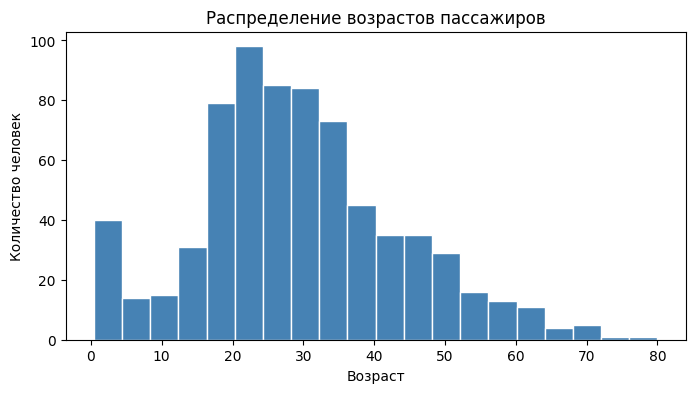

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['Age'].dropna(), bins='auto', color='steelblue', edgecolor='white')
ax.set(title='Распределение возрастов пассажиров', xlabel='Возраст', ylabel='Количество человек')
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

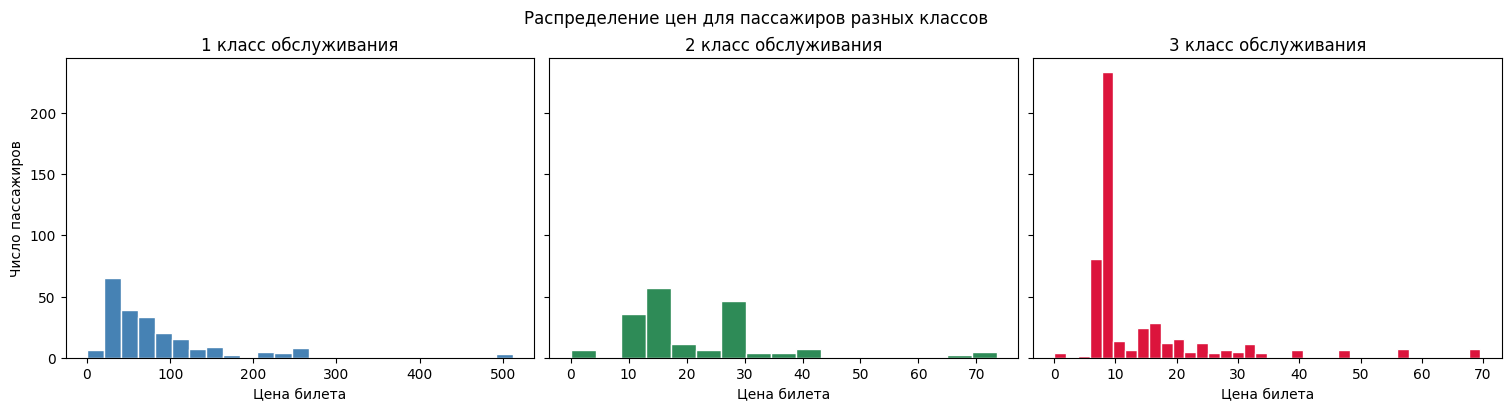

In [26]:
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout='constrained')

classes = [1, 2, 3]
colors = ['steelblue', 'seagreen', 'crimson']

for i, pclass in enumerate(classes):
    class_data = df[df['Pclass'] == pclass]

    ax_sub = axes[i]
    ax_sub.hist(class_data['Fare'].dropna(), bins='auto', color=colors[i], edgecolor='white')

    ax_sub.set_title(f'{pclass} класс обслуживания')
    ax_sub.set_xlabel('Цена билета')

axes[0].set_ylabel('Число пассажиров')
fig.suptitle('Распределение цен для пассажиров разных классов')

plt.show()

3. Постройте зависимость цены от возраста пассажира

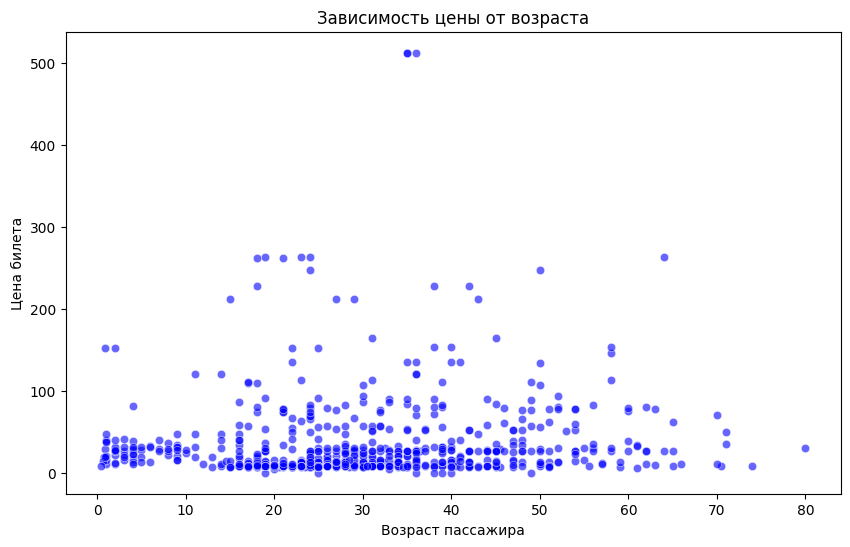

In [27]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Age', y='Fare', alpha=0.6, color='blue')

plt.title('Зависимость цены от возраста')
plt.xlabel('Возраст пассажира')
plt.ylabel('Цена билета')
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

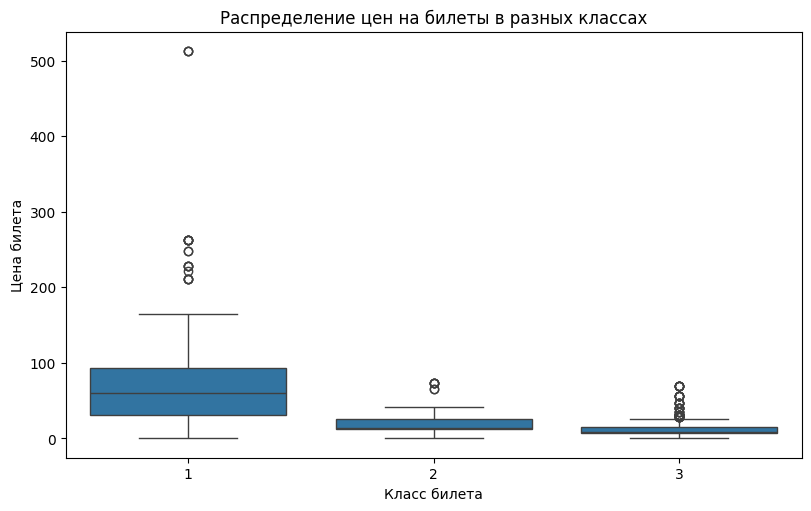

In [28]:
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
sns.boxplot(data=df, x='Pclass', y='Fare', ax=ax)

ax.set_title('Распределение цен на билеты в разных классах')
ax.set_xlabel('Класс билета')
ax.set_ylabel('Цена билета')
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

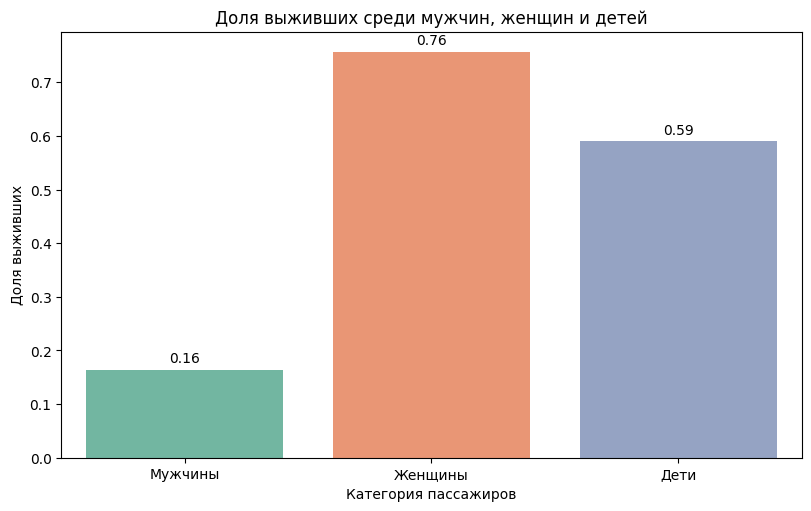

In [34]:
df['Category'] = 'Взрослые'
df.loc[df['Age'] < 16, 'Category'] = 'Дети'
df.loc[(df['Sex'] == 'female') & (df['Category'] == 'Взрослые'), 'Category'] = 'Женщины'
df.loc[(df['Sex'] == 'male') & (df['Category'] == 'Взрослые'), 'Category'] = 'Мужчины'

fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
sns.barplot(data=df, x='Category', y='Survived', hue='Category', palette='Set2', legend=False, errorbar=None, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3) 

ax.set_title('Доля выживших среди мужчин, женщин и детей')
ax.set_xlabel('Категория пассажиров')
ax.set_ylabel('Доля выживших')

plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

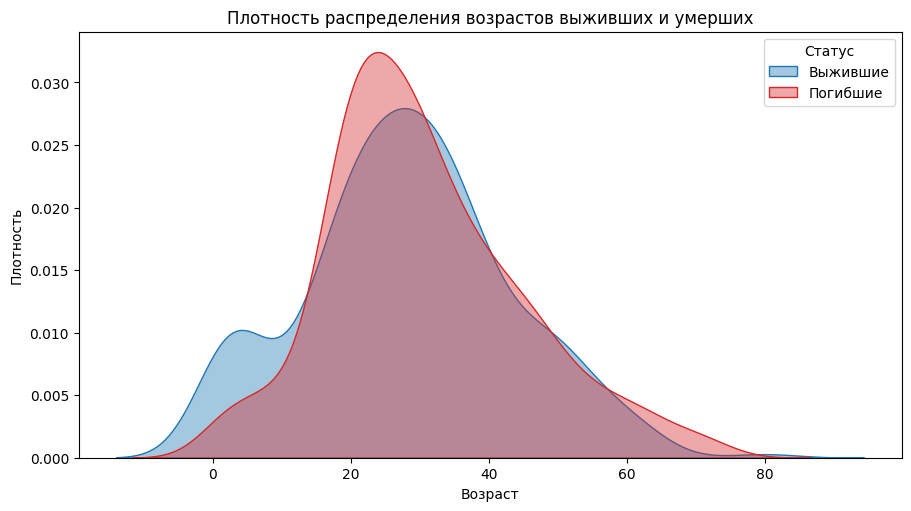

In [58]:
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')

age_surv = df[df['Survived'] == 1]['Age'].dropna()
age_dead = df[df['Survived'] == 0]['Age'].dropna()

sns.kdeplot(age_surv, ax=ax, label='Выжившие', fill=True, alpha=0.4, color='tab:blue')
sns.kdeplot(age_dead, ax=ax, label='Погибшие', fill=True, alpha=0.4, color='tab:red')

ax.set_title('Плотность распределения возрастов выживших и умерших')
ax.set_xlabel('Возраст')
ax.set_ylabel('Плотность')
ax.legend(title='Статус')

plt.show()

***Вывод***: У выживших наблюдается выраженный пик в детском возрасте, тогда как максимум погибших приходится на молодых людей 20–30 лет. Это наглядно подтверждает, что при эвакуации приоритет отдавался детям.

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

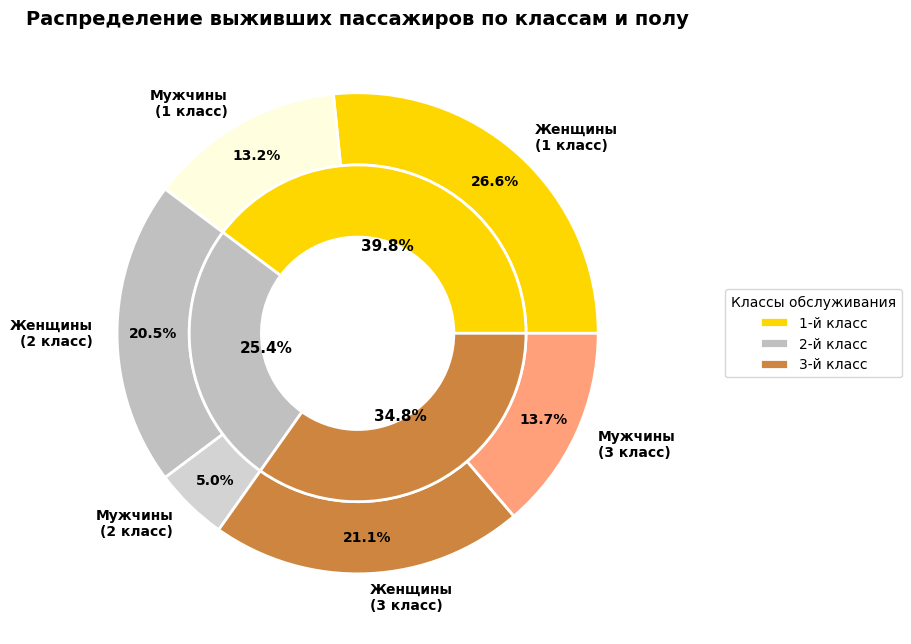

In [46]:
df_survived = df[df['Survived'] == 1]
counts = df_survived.groupby(['Pclass', 'Sex']).size()

inner_values = [counts[1].sum(), counts[2].sum(), counts[3].sum()]
inner_labels = ['1-й класс', '2-й класс', '3-й класс']

outer_values = [counts[1]['female'], counts[1]['male'], counts[2]['female'], counts[2]['male'], counts[3]['female'], counts[3]['male']]
outer_labels = [
    'Женщины\n(1 класс)', 'Мужчины\n(1 класс)', 
    'Женщины\n(2 класс)', 'Мужчины\n(2 класс)', 
    'Женщины\n(3 класс)', 'Мужчины\n(3 класс)'
]

inner_colors = ['gold', 'silver', 'peru']
outer_colors = [
    'gold', 'lightyellow',
    'silver', 'lightgray',
    'peru', 'lightsalmon'
]

fig, ax = plt.subplots(figsize=(9, 9), layout='constrained')
size = 0.3

wedges_out, texts_out, autotexts_out = ax.pie(
    outer_values, 
    radius=1, 
    labels=outer_labels,
    colors=outer_colors,
    autopct='%1.1f%%',
    pctdistance=0.85,
    wedgeprops=dict(width=size, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10, fontweight='bold')
)

wedges_in, texts_in, autotexts_in = ax.pie(
    inner_values, 
    radius=1-size, 
    colors=inner_colors,
    autopct='%1.1f%%',
    pctdistance=0.55,
    wedgeprops=dict(width=size, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11, weight='bold')
)

ax.legend(wedges_in, inner_labels, title="Классы обслуживания", loc="center left", bbox_to_anchor=(1.1, 0, 0.5, 1))
ax.set_title('Распределение выживших пассажиров по классам и полу', fontsize=14, fontweight='bold')

plt.show()
